In [4]:
# Select the backend before importing Keras. Restart the kernel after changing it.
import os

os.environ["KERAS_BACKEND"] = "torch"
import math

from torch.utils.data import TensorDataset
from keras.src.callbacks import early_stopping

import keras
import torch
import matplotlib.pyplot as plt

assert keras.backend.backend() == "torch", "Restart the kernel and run this cell first."


# Set global policy to leverage Metal's FP16 architecture
# policy = keras.mixed_precision.Policy("mixed_bfloat16")
# keras.mixed_precision.set_global_policy(policy)


def plot_samples(data,
                 n=5,
                 max_cols=5,
                 cmap="tab20",
                 filename=None
                 ):
    n = min(len(data), n)
    if n < max_cols:
        rows = 1
        cols = n
    else:
        rows = math.ceil(n / max_cols)
        cols = max_cols
    print(f"rows: {rows}, cols: {cols}")
    fig, ax = plt.subplots(nrows=rows, ncols=cols, sharex=True, sharey=True, figsize=(20, 10))
    #ax = ax.flatten()
    index = 0
    for i in range(rows):
        for j in range(cols):
            img = data[index]
            index += 1
            ax[i, j].imshow(img, cmap=cmap, interpolation='nearest')
            if index >= n:
                break
    plt.tight_layout()
    plt.show()
    if filename:
        plt.savefig(filename, dpi=300)


from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay)


def model_metrics(model, dataloader):
    loss, accuracy = model.evaluate(dataloader, verbose=0)
    y_pred = model.predict(dataloader).argmax(axis=1)
    y_true = torch.cat([y for x, y in dataloader], dim=0)
    precision = precision_score(y_true, y_pred, average="macro")
    recall = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")
    print(
            f" Loss: {loss:.4f} \n Accuracy: {accuracy:.4f} \n Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}"
            )
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap=plt.cm.Blues)


## Data Preparation

(60000, 28, 28)
X_train shape: (60000, 28, 28), nr. of classes: 10
Min: 0, Max: 9
rows: 4, cols: 5


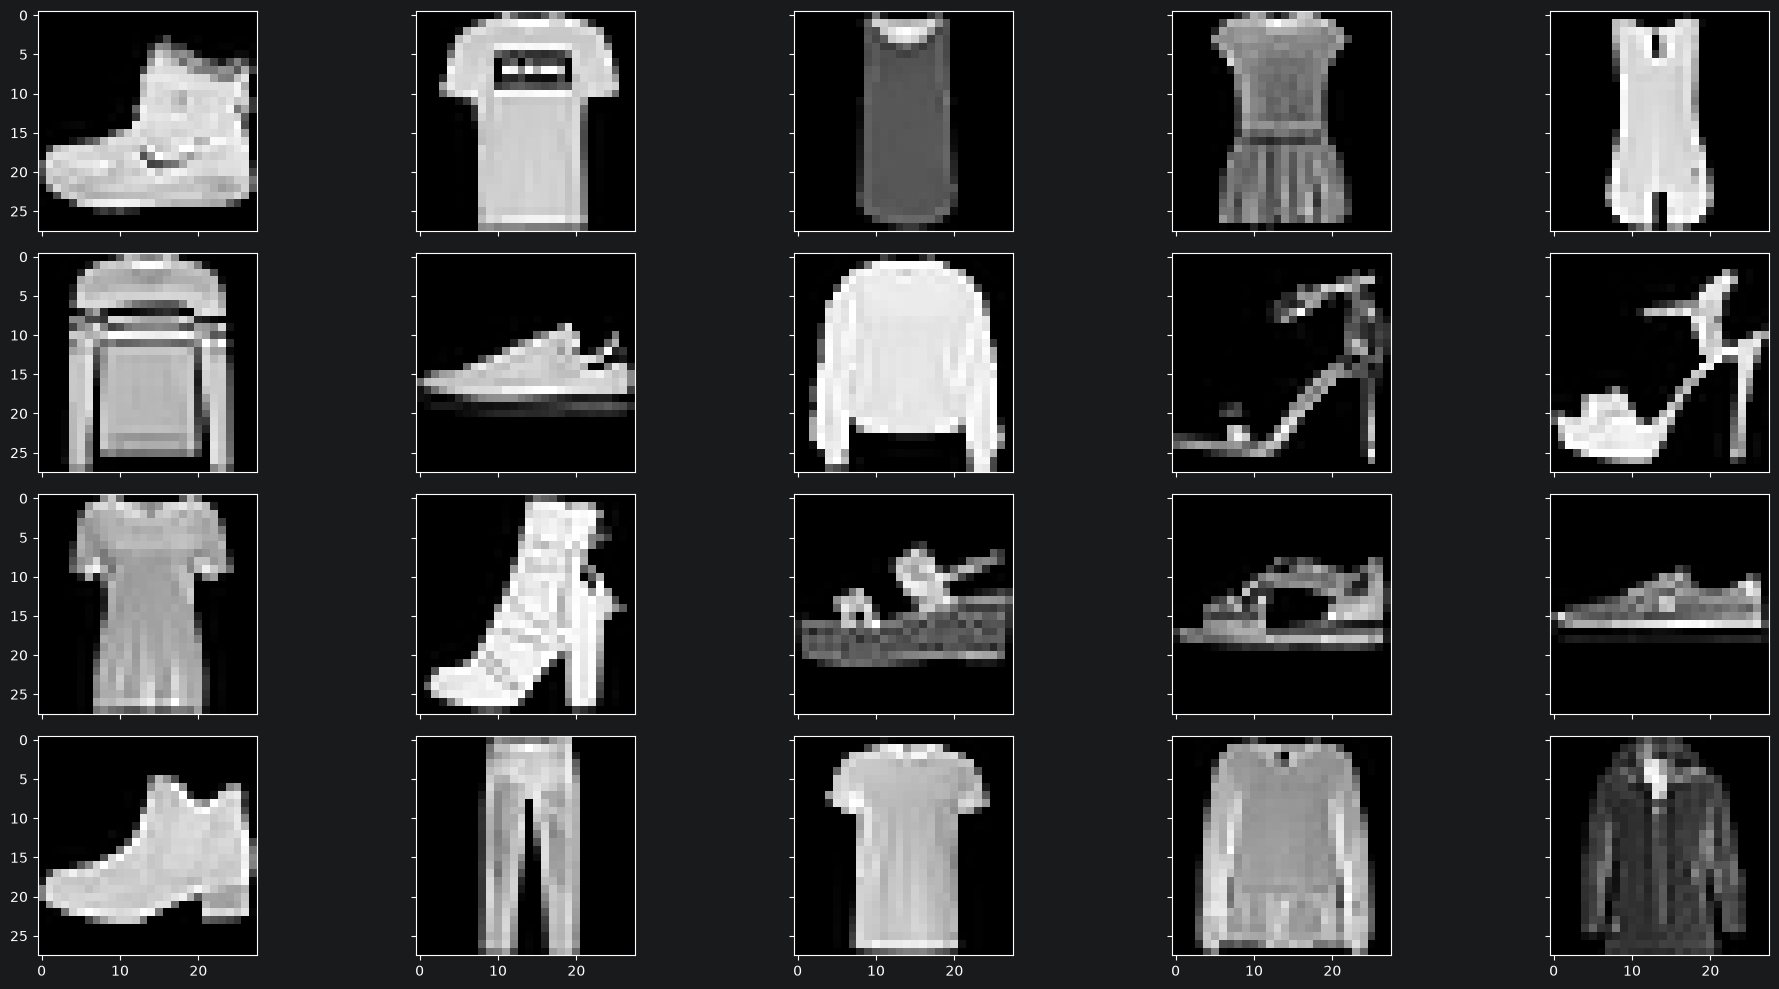

In [5]:
(mnist_images, mnist_labels), (mnist_images_test, mnist_labels_test) = keras.datasets.fashion_mnist.load_data()
print(mnist_images.shape)

X_train = mnist_images.astype("float32") / 255.0
y_train = mnist_labels.astype("int32")
X_test = mnist_images_test.astype("float32") / 255.0
y_test = mnist_labels_test.astype("int32")

print(f"X_train shape: {X_train.shape}, nr. of classes: {len(set(y_train))}")
print(f"Min: {y_train.min()}, Max: {y_train.max()}")

plot_samples(X_train, n=20, cmap="gray")

In [6]:
train_dataset = torch.utils.data.TensorDataset(torch.as_tensor(X_train), torch.as_tensor(y_train))
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
eval_dataset = torch.utils.data.TensorDataset(torch.as_tensor(X_test), torch.as_tensor(y_test))
eval_dataloader = torch.utils.data.DataLoader(eval_dataset, batch_size=8, shuffle=False)

## Baseline Model

In [7]:
base_model = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
base_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/100


W1102 14:18:25.615000 9759 .venv/lib/python3.14/site-packages/torch/_inductor/utils.py:1806] [1/0_1] Not enough SMs to use max_autotune_gemm mode


938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.7832 - loss: 0.6554 - val_accuracy: 0.8210 - val_loss: 0.5321
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8365 - loss: 0.4828 - val_accuracy: 0.8315 - val_loss: 0.4903
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8459 - loss: 0.4497 - val_accuracy: 0.8376 - val_loss: 0.4710
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8514 - loss: 0.4326 - val_accuracy: 0.8382 - val_loss: 0.4610
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8559 - loss: 0.4225 - val_accuracy: 0.8413 - val_loss: 0.4568
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8572 - loss: 0.4144 - val_accuracy: 0.8430 - val_loss: 0.4547
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8592 - loss: 0.4085 - val_accuracy: 0.8426 - val_loss: 0.4540
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 831us/step   
 Loss: 0.4568 
 Accuracy: 0.8413 
 Precision: 0.8424, Recal

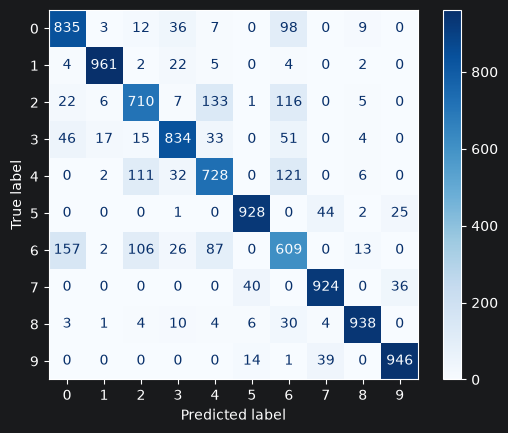

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
base_model.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(base_model, eval_dataloader)

## Hidden Layer Models

In [46]:
m1 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m1.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
m1.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_16 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
 26/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5637 - loss: 1.5429  

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9121 - loss: 0.3144 - val_accuracy: 0.9484 - val_loss: 0.1785
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9577 - loss: 0.1485 - val_accuracy: 0.9631 - val_loss: 0.1233
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9690 - loss: 0.1057 - val_accuracy: 0.9709 - val_loss: 0.1021
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9758 - loss: 0.0814 - val_accuracy: 0.9719 - val_loss: 0.0914
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9801 - loss: 0.0654 - val_accuracy: 0.9715 - val_loss: 0.0918
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9833 - loss: 0.0545 - val_accuracy: 0.9711 - val_loss: 0.0900
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 966us/step
 Loss: 0.0914 
 Accuracy: 0.9719 
 Precision: 0.9719, Recall: 0.9717, F1: 0.9718


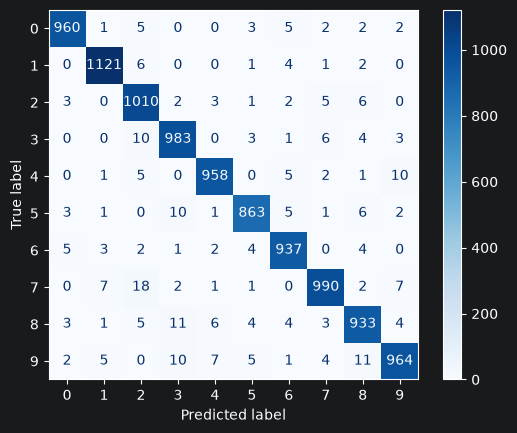

In [47]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
m1.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(m1, eval_dataloader)

In [48]:
m1.save("../models/mnist_fashiob_100_10.keras")

In [27]:
m2 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m2.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
m2.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 30)             │        23,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,790 (96.84 KB)

 Trainable params: 24,790 (96.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
 25/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3044 - loss: 2.0589  

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8777 - loss: 0.4232 - val_accuracy: 0.9310 - val_loss: 0.2346
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9392 - loss: 0.2115 - val_accuracy: 0.9428 - val_loss: 0.1996
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9493 - loss: 0.1725 - val_accuracy: 0.9519 - val_loss: 0.1672
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9559 - loss: 0.1495 - val_accuracy: 0.9544 - val_loss: 0.1553
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9607 - loss: 0.1330 - val_accuracy: 0.9548 - val_loss: 0.1478
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9645 - loss: 0.1199 - val_accuracy: 0.9586 - val_loss: 0.1431
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9671 - loss: 0.1089 - val_accuracy: 0.9638 - val_loss: 0.1327
Epoch 8/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9690 - loss: 0.1005 - val_accuracy: 0.959

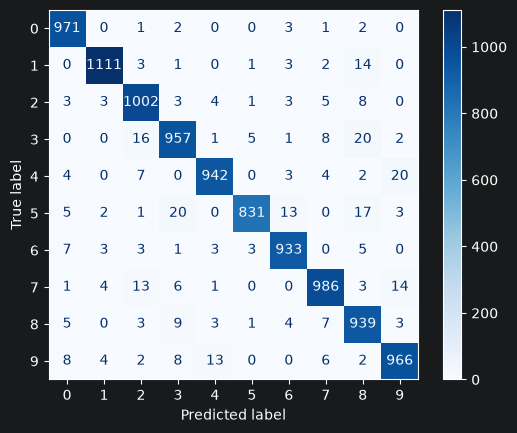

In [28]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
m2.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(m2, eval_dataloader)

In [29]:
m3 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m3.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
m3.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_11 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 30)             │        23,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 30)             │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,650 (104.10 KB)

 Trainable params: 26,650 (104.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
 16/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.1963 - loss: 2.2516  

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8672 - loss: 0.4381 - val_accuracy: 0.9393 - val_loss: 0.2084
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9428 - loss: 0.1919 - val_accuracy: 0.9481 - val_loss: 0.1806
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9547 - loss: 0.1527 - val_accuracy: 0.9544 - val_loss: 0.1526
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9601 - loss: 0.1318 - val_accuracy: 0.9553 - val_loss: 0.1502
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9646 - loss: 0.1176 - val_accuracy: 0.9637 - val_loss: 0.1298
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9681 - loss: 0.1049 - val_accuracy: 0.9621 - val_loss: 0.1303
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9704 - loss: 0.0957 - val_accuracy: 0.9645 - val_loss: 0.1229
Epoch 8/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9728 - loss: 0.0883 - val_accuracy: 0.96

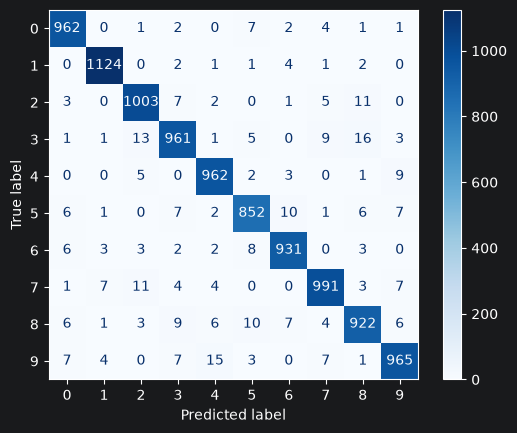

In [30]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
m3.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(m3, eval_dataloader)

In [35]:
m3.save("../models/mnist_fashiob_30_30_30_30_10.keras")

In [33]:
m4 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(40, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(20, activation="relu"),
                keras.layers.Dense(20, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m4.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
m4.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_13 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 40)             │        31,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 30)             │         1,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,880 (132.34 KB)

 Trainable params: 33,880 (132.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
 14/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.1853 - loss: 2.1986  

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8618 - loss: 0.4526 - val_accuracy: 0.9347 - val_loss: 0.2137
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9437 - loss: 0.1912 - val_accuracy: 0.9507 - val_loss: 0.1633
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9554 - loss: 0.1491 - val_accuracy: 0.9547 - val_loss: 0.1504
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9617 - loss: 0.1252 - val_accuracy: 0.9595 - val_loss: 0.1331
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9676 - loss: 0.1073 - val_accuracy: 0.9638 - val_loss: 0.1225
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9720 - loss: 0.0927 - val_accuracy: 0.9661 - val_loss: 0.1147
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9751 - loss: 0.0817 - val_accuracy: 0.9612 - val_loss: 0.1301
Epoch 8/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9775 - loss: 0.0737 - val_accuracy:

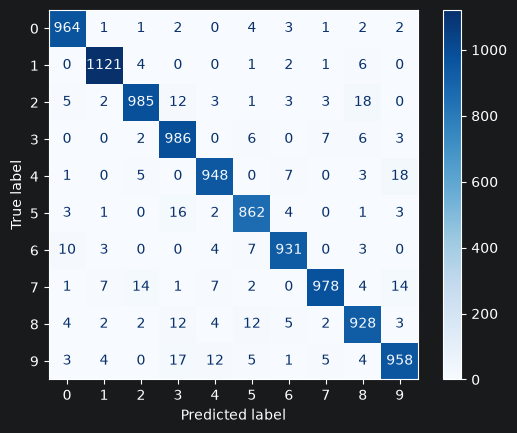

In [34]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
m4.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(m4, eval_dataloader)

In [37]:
m5 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(10, activation="softmax")
                ]
        )
m5.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
m5.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_14 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 10)             │           310 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,840 (319.69 KB)

 Trainable params: 81,840 (319.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
 14/938 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.4107 - loss: 1.9610  

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


934/938 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9137 - loss: 0.2994

W1102 12:47:25.674000 81411 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8] torch._dynamo hit config.recompile_limit (8)
W1102 12:47:25.674000 81411 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]    function: 'one_step_on_data' (/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/backend/torch/trainer.py:142)
W1102 12:47:25.674000 81411 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]    last reason: 3/7: self.name == 'sequential_13'                             # return backend.name_scope(self.name, caller=self)  # keras/src/layers/layer.py:1768 in _open_name_scope
W1102 12:47:25.674000 81411 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8] User stack trace:
W1102 12:47:25.674000 81411 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]   File "/Users/thomasbayer/Projects/PycharmProjects/ml/dl_

938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9139 - loss: 0.2989 - val_accuracy: 0.9526 - val_loss: 0.1539
Epoch 2/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9617 - loss: 0.1283 - val_accuracy: 0.9671 - val_loss: 0.1085
Epoch 3/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9728 - loss: 0.0910 - val_accuracy: 0.9710 - val_loss: 0.1006
Epoch 4/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9793 - loss: 0.0690 - val_accuracy: 0.9749 - val_loss: 0.0840
Epoch 5/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9834 - loss: 0.0542 - val_accuracy: 0.9766 - val_loss: 0.0783
Epoch 6/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9865 - loss: 0.0430 - val_accuracy: 0.9744 - val_loss: 0.0876
Epoch 7/100
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9883 - loss: 0.0371 - val_accuracy: 0.9761 - val_loss: 0.0830
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 676us/step   
 Loss: 0.0783 
 Accuracy: 0.9766 
 Precision: 0.976

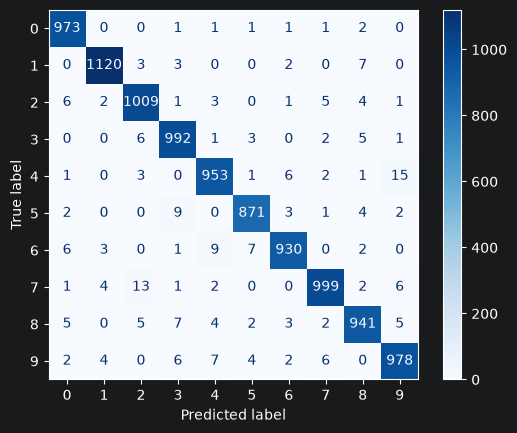

In [38]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
m5.fit(
        train_dataloader,
        validation_data=eval_dataloader,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(m5, eval_dataloader)

In [39]:
m5.save("../models/mnist_fashiob_100_30_10.keras")

## 11 Classes

In [28]:
(mnist_digits, mnist_d_labels), (mnist_digits_test, mnist_d_labels_test) = keras.datasets.fashion_mnist.load_data()

Xd_train = mnist_digits.astype("float32") / 255.0
yd_train = mnist_d_labels.astype("int32")
yd_train_10 = torch.tensor([10] * len(Xd_train), dtype=torch.int32)

Xd_test = mnist_digits_test.astype("float32") / 255.0
yd_test = mnist_d_labels_test.astype("int32")
yd_test_10 = torch.tensor([10] * len(Xd_test), dtype=torch.int32)

In [13]:
y_pred_digits = base_model.predict(Xd_train[:10]).argmax(axis=1)
print(f"Predictions: {y_pred_digits}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 656ms/step
Predictions: [9 0 0 0 3 2 7 2 5 5]


In [32]:
def predict(model, images, threshold=0.9):
    y_proba = model.predict(images)
    y_pred = y_proba.argmax(axis=1)
    y_predict = [int(y_pred[i]) if y_proba[i, y_pred[i]] >= threshold else -1 for i in range(len(y_pred))]
    return y_predict


predict(base_model, Xd_train[:10], threshold=0.7)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


[9, 0, -1, -1, -1, 2, 7, -1, 5, 5]

In [24]:
train_digits_11 = TensorDataset(torch.as_tensor(Xd_test[:8000]), torch.as_tensor(yd_test_10[:8000]))
train_dataset_11 = torch.utils.data.ConcatDataset([train_dataset, train_digits_11])
train_dataloader_11 = torch.utils.data.DataLoader(train_dataset_11, batch_size=64, shuffle=True)

for x, y in train_dataloader_11:
    print(f"x shape: {x.shape}, y shape: {y.shape}")
    print(f"y unique: {torch.unique(y)}")
    print(f"y: {y}")
    break

eval_digits_11 = TensorDataset(torch.as_tensor(Xd_test[8000:]), torch.as_tensor(yd_test_10[8000:]))
eval_dataset_11 = torch.utils.data.ConcatDataset([eval_dataset, eval_digits_11])
eval_dataloader_11 = torch.utils.data.DataLoader(eval_dataset_11, batch_size=8, shuffle=False)

x shape: torch.Size([64, 28, 28]), y shape: torch.Size([64])
y unique: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10], dtype=torch.int32)
y: tensor([ 9,  3,  9,  8,  1,  0,  6,  8,  4,  4,  2,  5,  0,  7,  0,  4,  4, 10,
         8,  0, 10,  3,  8,  7,  7,  6, 10,  3,  0,  3,  6,  7,  2,  9, 10,  4,
         5,  6,  3,  5,  9,  2,  6,  8,  4,  3,  8, 10,  2,  8,  2,  7, 10,  6,
         4,  1,  3,  4,  3, 10,  8,  2,  4,  5], dtype=torch.int32)


In [ ]:
base_model_11 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(11, activation="softmax")
                ]
        )
base_model_11.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.002
        )
base_model_11.fit(
        train_dataloader_11,
        validation_data=eval_dataloader_11,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(base_model_11, eval_dataloader_11)

In [ ]:
model_11 = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(11, activation="softmax")
                ]
        )
model_11.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
model_11.fit(
        train_dataloader_11,
        validation_data=eval_dataloader_11,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(model_11, eval_dataloader_11)

Epoch 1/100
1022/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7085 - loss: 0.8733

Epoch 1/100
  16/1063 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.3535 - loss: 1.8138   

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


1058/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7179 - loss: 0.8426

W1102 14:33:43.847000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8] torch._dynamo hit config.recompile_limit (8)
W1102 14:33:43.847000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]    function: 'one_step_on_data' (/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/backend/torch/trainer.py:142)
W1102 14:33:43.847000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]    last reason: 3/7: self.name == 'sequential_7'                              # return backend.name_scope(self.name, caller=self)  # keras/src/layers/layer.py:1768 in _open_name_scope
W1102 14:33:43.847000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8] User stack trace:
W1102 14:33:43.847000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [3/8]   File "/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winte

1063/1063 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.7182 - loss: 0.8418 - val_accuracy: 0.6934 - val_loss: 0.8855
Epoch 2/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.7599 - loss: 0.7108 - val_accuracy: 0.7047 - val_loss: 0.8245
Epoch 3/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7724 - loss: 0.6750 - val_accuracy: 0.7173 - val_loss: 0.8008
Epoch 4/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7784 - loss: 0.6515 - val_accuracy: 0.7158 - val_loss: 0.8140
Epoch 5/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.7842 - loss: 0.6340 - val_accuracy: 0.7190 - val_loss: 0.7851
Epoch 6/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.7890 - loss: 0.6165 - val_accuracy: 0.7261 - val_loss: 0.7687
Epoch 7/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.7933 - loss: 0.6051 - val_accuracy: 0.7293 - val_loss: 0.7689
Epoch 8/100
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.7971 - los

W1102 14:35:17.107000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [4/8] torch._dynamo hit config.recompile_limit (8)
W1102 14:35:17.107000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [4/8]    function: 'one_step_on_data' (/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/backend/torch/trainer.py:163)
W1102 14:35:17.107000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [4/8]    last reason: 4/7: self.name == 'sequential_7'                              # return backend.name_scope(self.name, caller=self)  # keras/src/layers/layer.py:1768 in _open_name_scope
W1102 14:35:17.107000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [4/8] User stack trace:
W1102 14:35:17.107000 9759 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [4/8]   File "/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winte

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
 Loss: 0.7687 
 Accuracy: 0.7261 
 Precision: 0.6716, Recall: 0.7920, F1: 0.7181


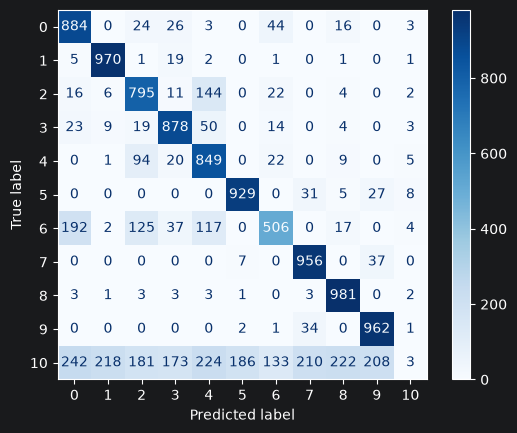

In [27]:
model_11b = keras.Sequential(
        [
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(200, activation="relu"),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(11, activation="softmax")
                ]
        )
model_11b.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
        jit_compile=True
        )
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        min_delta=0.003
        )
model_11b.fit(
        train_dataloader_11,
        validation_data=eval_dataloader_11,
        epochs=100,
        verbose=1,
        callbacks=[early_stopping]
        )
model_metrics(model_11b, eval_dataloader_11)